John S. Anvik, 2026  
University of Lethbridge Student ID: 001224816

Import Packages

In [1]:
library(tidyverse)
library(tidymodels)
library(rpart.plot)
library(vip)
library(ranger)

set.seed(42)

Warning message:
"package 'tidyverse' was built under R version 4.5.3"
── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
── Attaching packages ────────────────────────────────────── tidymodels 1.4.1 ──

✔ broom        1.0.10     ✔ rsample      1.3.1 
✔ dials        1.4.2      ✔ tailor       0.1.0 
✔ infer        1.0.9      ✔ tune         2.0.1 
✔ modeldata    1.5.1      ✔ workflows    1.3.0 
✔ parsnip      1.3.3      ✔ workflowsets 1.1.1 
✔ recipes      1.3.1      ✔ yardstick    1.3.2 

── Conflicts ─────────────────────

Load candidate-level data exported by notebook 2

In [2]:
candidate_files <- list.files("data/by_id", pattern = "_candidate_classification\\.csv$", full.names = TRUE)

# To test only a single classifier, uncomment the next line:
candidate_files <- candidate_files[1]

model_data_by_male <- flatten(map(candidate_files, function(candidate_file) {
    song_data <- read_csv(candidate_file, show_col_types = FALSE)
    focal_ids <- song_data %>% distinct(ID) %>% pull(ID)
    focal_numbers <- song_data %>% pull(male_number) %>% as.character() %>% unique() %>% na.omit()
    if (length(focal_ids) != 1 || length(focal_numbers) == 0) {
        stop(sprintf("Expected one focal ID and at least one male_number in %s", candidate_file))
    }
    map(focal_numbers, function(focal_number) {
        focal_rows <- song_data %>% filter(as.character(male_number) == focal_number)
        male_prefix <- paste0("M", focal_number)
        required_columns <- c(
            "event_id", "candidate_ust", "match", "candidate_n_ust_window",
            paste0("candidate_matches_", male_prefix, "_1_last_UST"),
            paste0("candidate_matches_", male_prefix, "_2_last_UST"),
            paste0("time_since_", male_prefix, "_1_last_song"),
            paste0("time_since_", male_prefix, "_2_last_song")
        )
        missing_columns <- setdiff(required_columns, names(focal_rows))
        if (length(missing_columns) > 0) {
            stop(sprintf("Missing required columns in %s for %s: %s", candidate_file, male_prefix, paste(missing_columns, collapse = ", ")))
        }
        focal_rows %>%
            transmute(
                focal_male = paste0(focal_ids, "_", male_prefix),
                focal_id = focal_ids,
                male_number = focal_number,
                event_id,
                candidate_ust = as.factor(as.character(candidate_ust)),
                match,
                candidate_n_ust_window,
                focal_last_1_candidate = .data[[paste0("candidate_matches_", male_prefix, "_1_last_UST")]],
                focal_last_2_candidate = .data[[paste0("candidate_matches_", male_prefix, "_2_last_UST")]],
                focal_time_since_last_1 = .data[[paste0("time_since_", male_prefix, "_1_last_song")]],
                focal_time_since_last_2 = .data[[paste0("time_since_", male_prefix, "_2_last_song")]]
            ) %>%
            mutate(match_class = factor(if_else(match == 1, "match", "no_match"), levels = c("no_match", "match"))) %>%
            select(-match)
    })
}))
names(model_data_by_male) <- map_chr(model_data_by_male, ~ unique(.x$focal_male))

walk(model_data_by_male, function(male_data) {
    event_checks <- male_data %>% group_by(event_id) %>% summarise(n_candidates = n(), n_matches = sum(match_class == "match"), .groups = "drop")
    if (any(event_checks$n_candidates < 2) || any(event_checks$n_matches != 1)) {
        stop(sprintf("Invalid candidate events for %s", unique(male_data$focal_male)))
    }
})

In [3]:
map_dfr(model_data_by_male, ~ .x %>% summarise(
    focal_male = first(focal_male),
    n_events = n_distinct(event_id),
    n_candidate_rows = n(),
    n_song_types = n_distinct(candidate_ust)
))

focal_male,n_events,n_candidate_rows,n_song_types
<chr>,<int>,<int>,<int>
DgTbO_M5,1167,32676,28
DgTbO_M6,999,27972,28


Train/test split and cross-validation

In [4]:
male_splits <- map(model_data_by_male, ~ group_initial_split(.x, group = event_id, prop = 0.7))
male_train_data <- map(male_splits, training)
male_test_data <- map(male_splits, testing)
male_vfolds <- map(male_train_data, ~ group_vfold_cv(.x, group = event_id, v = 5))

Data preprocessing using a recipe

In [5]:
male_recipes <- map(male_train_data, ~ recipe(match_class ~ ., data = .x) %>% update_role(focal_male, focal_id, male_number, event_id, candidate_ust, new_role = "id") %>% step_impute_median(all_numeric_predictors()))

Tune using top-1 candidate-selection accuracy

In [6]:
top1_candidate_accuracy <- function(predictions) {
    predictions %>% group_by(event_id) %>% slice_max(.pred_match, n = 1, with_ties = FALSE) %>%
        summarise(correct = any(match_class == "match"), .groups = "drop") %>%
        summarise(top1_accuracy = mean(correct)) %>% pull(top1_accuracy)
}

tune_grid <- tidyr::crossing(mtry = c(1, 2, 3, 4, 5), min_n = c(2, 5, 10, 15, 20))
fit_one_male <- function(male_data, train_data, test_data, vfolds, model_recipe) {
    focal_male <- unique(male_data$focal_male)
    tuning_results <- map_dfr(seq_len(nrow(tune_grid)), function(i) {
        spec <- rand_forest(mtry = tune_grid$mtry[i], trees = 1000, min_n = tune_grid$min_n[i]) %>% set_engine("ranger", importance = "impurity", probability = TRUE) %>% set_mode("classification")
        wf <- workflow() %>% add_recipe(model_recipe) %>% add_model(spec)
        fold_results <- map_dfr(vfolds$splits, function(split) {
            fit_i <- fit(wf, analysis(split))
            assessment_data <- assessment(split)
            predictions <- predict(fit_i, assessment_data, type = "prob") %>% bind_cols(assessment_data %>% select(event_id, match_class))
            tibble(top1_accuracy = top1_candidate_accuracy(predictions))
        })
        tibble(mtry = tune_grid$mtry[i], min_n = tune_grid$min_n[i], mean_top1_accuracy = mean(fold_results$top1_accuracy), std_error = sd(fold_results$top1_accuracy) / sqrt(nrow(fold_results)))
    }) %>% arrange(desc(mean_top1_accuracy), std_error)
    best_params <- tuning_results %>% slice(1)
    final_spec <- rand_forest(mtry = best_params$mtry, trees = 1000, min_n = best_params$min_n) %>% set_engine("ranger", importance = "impurity", probability = TRUE) %>% set_mode("classification")
    final_model <- workflow() %>% add_recipe(model_recipe) %>% add_model(final_spec) %>% fit(data = train_data)
    test_predictions <- predict(final_model, test_data, type = "prob") %>% bind_cols(test_data %>% select(focal_male, event_id, candidate_ust, match_class))
    event_predictions <- test_predictions %>% group_by(event_id) %>% arrange(desc(.pred_match), .by_group = TRUE) %>% summarise(focal_male = first(focal_male), predicted_song_type = first(candidate_ust), actual_song_type = candidate_ust[match_class == "match"][1], .groups = "drop") %>% mutate(predicted_song_type = factor(predicted_song_type, levels = levels(male_data$candidate_ust)), actual_song_type = factor(actual_song_type, levels = levels(male_data$candidate_ust)))
    ranking_metrics <- test_predictions %>% group_by(event_id) %>% arrange(desc(.pred_match), .by_group = TRUE) %>% mutate(candidate_rank = row_number(), actual_match = match_class == "match") %>% summarise(top1_correct = any(candidate_rank == 1 & actual_match), top3_correct = any(candidate_rank <= 3 & actual_match), reciprocal_rank = 1 / min(candidate_rank[actual_match]), correct_rank = min(candidate_rank[actual_match]), .groups = "drop")
    metrics <- tibble(focal_male = focal_male, n_test_events = nrow(event_predictions), accuracy = mean(ranking_metrics$top1_correct), macro_precision = precision(event_predictions, truth = actual_song_type, estimate = predicted_song_type, estimator = "macro")$.estimate, macro_recall = recall(event_predictions, truth = actual_song_type, estimate = predicted_song_type, estimator = "macro")$.estimate, top3_recall = mean(ranking_metrics$top3_correct), mean_reciprocal_rank = mean(ranking_metrics$reciprocal_rank), mean_rank = mean(ranking_metrics$correct_rank))
    list(focal_male = focal_male, tuning_results = tuning_results, best_params = best_params, model = final_model, test_predictions = test_predictions, event_predictions = event_predictions, metrics = metrics)
}
male_results <- pmap(list(model_data_by_male, male_train_data, male_test_data, male_vfolds, male_recipes), fit_one_male)

Warning message:
"While computing multiclass `precision()`, some levels had no predicted events
(i.e. `true_positive + false_positive = 0`).
Precision is undefined in this case, and those levels will be removed from the
averaged result.
Note that the following number of true events actually occurred for each
problematic event level:
'154': 2, '157': 0, '158': 0, '159': 0, '160': 0, '161': 0, '162': 0, '163': 0,
'164': 0, '30': 0"
Warning message:
"While computing multiclass `recall()`, some levels had no true events (i.e.
`true_positive + false_negative = 0`).
Recall is undefined in this case, and those levels will be removed from the
averaged result.
Note that the following number of predicted events actually occurred for each
problematic event level:
'13': 15, '155': 1, '157': 0, '158': 0, '159': 0, '160': 0, '161': 0, '162': 0,
'163': 0, '164': 0, '30': 0, '5': 7"
Warning message:
"While computing multiclass `precision()`, some levels had no predicted events
(i.e. `true_positive + f

Select best hyperparameters and refit on all training data

In [7]:
map_dfr(male_results, "best_params") %>% select(mtry, min_n, mean_top1_accuracy, std_error)

mtry,min_n,mean_top1_accuracy,std_error
<dbl>,<dbl>,<dbl>,<dbl>
1,15,0.1089705,0.007720579
2,5,0.1587359,0.016082001


Evaluate held-out test data

In [8]:
per_male_metrics <- map_dfr(male_results, "metrics")
per_male_metrics

focal_male,n_test_events,accuracy,macro_precision,macro_recall,top3_recall,mean_reciprocal_rank,mean_rank
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
DgTbO_M5,350,0.1142857,0.08471536,0.09327125,0.2514286,0.2425805,13.25143
DgTbO_M6,300,0.1266667,0.10760116,0.08062111,0.2766667,0.2676404,11.39667


Confusion matrix

In [9]:
map(male_results, ~ conf_mat(.x$event_predictions, truth = actual_song_type, estimate = predicted_song_type))

$DgTbO_M5
          Truth
Prediction  1 10 11 12 13 15 153 154 155 156 157 158 159 160 161 162 163 164 20
       1    4  2  2  0  0  0   5   0   0   0   0   0   0   0   0   0   0   0 10
       10   4  7  6  2  0  0   4   0   0   0   0   0   0   0   0   0   0   0 13
       11   0  0  0  0  0  0   1   0   0   0   0   0   0   0   0   0   0   0  1
       12   0  0  2  0  0  1   0   0   0   0   0   0   0   0   0   0   0   0  3
       13   1  2  1  0  0  0   1   0   0   0   0   0   0   0   0   0   0   0  5
       15   0  1  0  0  0  0   0   0   0   0   0   0   0   0   0   0   0   0  2
       153  2  0  0  0  0  0   4   0   0   0   0   0   0   0   0   0   0   0  4
       154  0  0  0  0  0  0   0   0   0   0   0   0   0   0   0   0   0   0  0
       155  0  0  0  0  0  0   0   0   0   0   0   0   0   0   0   0   0   0  1
       156  0  0  0  0  0  0   0   0   0   0   0   0   0   0   0   0   0   0  0
       157  0  0  0  0  0  0   0   0   0   0   0   0   0   0   0   0   0   0  0
       158  0 

Feature importance

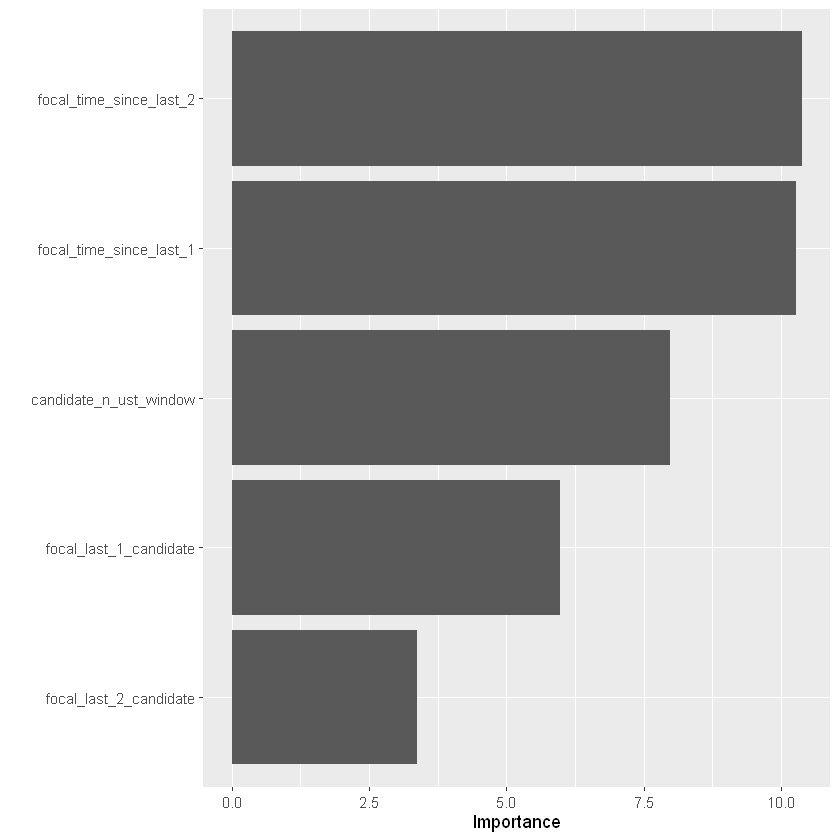

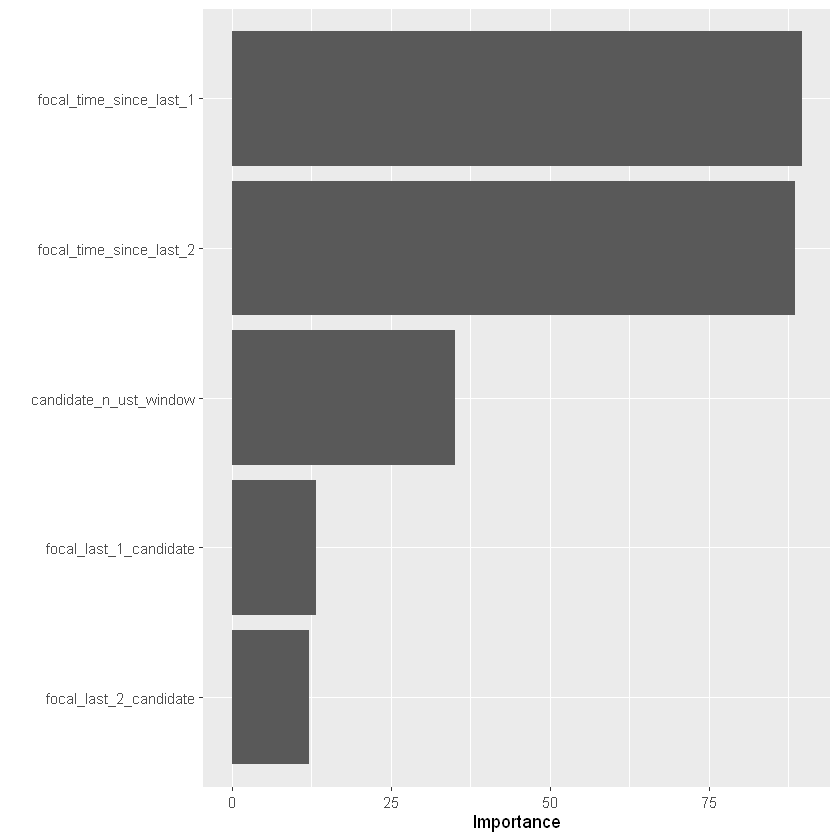

In [10]:
walk(male_results, ~ print(vip(.x$model %>% extract_fit_engine(), num_features = 5)))

Candidate-ranking metrics

In [11]:
per_male_metrics %>% summarise(macro_accuracy = mean(accuracy), macro_top3_recall = mean(top3_recall), macro_mean_reciprocal_rank = mean(mean_reciprocal_rank), macro_mean_rank = mean(mean_rank))

macro_accuracy,macro_top3_recall,macro_mean_reciprocal_rank,macro_mean_rank
<dbl>,<dbl>,<dbl>,<dbl>
0.1204762,0.2640476,0.2551105,12.32405
